# vRAN energy — trustworthy AI for **regression**

The vRAN dataset measures BBU **power consumption** and radio/compute configuration. Trust pillars adapt to a continuous target: robustness becomes *noise drift* (R² vs Gaussian noise), fairness becomes *per-platform error gaps*, and DP uses input perturbation.

In [1]:
# --- bootstrap: make the `trustoran` engineering package importable ---------
import sys, pathlib
REPO = pathlib.Path.cwd().resolve()
while not (REPO / "py" / "trustoran").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "py"))

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from trustoran import config as C
from trustoran.data import build_dataset, train_test_split_dataset
from trustoran.data.loaders import available_datasets
from trustoran.models import make_model
from trustoran.pipeline.engine import TrustPipeline, PILLARS, DATASET_PROFILES
from trustoran.viz import plotting as VZ
from trustoran.trust import explainability as EX, robustness as RB, fairness as FA, privacy as PR

print("repo root :", REPO)
print("datasets  :", available_datasets())
print("pillars   :", PILLARS)

repo root : E:\可信AI
datasets  : ['cci_a1sd', 'cci_a1sd_binary', 'ddos_pcap', 'vran_energy', 'vran_application', 'vran_computing']
pillars   : ('explainability', 'robustness', 'fairness', 'privacy')


{'name': 'vran_energy', 'task': 'regression', 'n_samples': 18893, 'n_features': 16, 'feature_names': ['BW', 'TM', 'traffic_load', 'txgain', 'selected_mcs', 'selected_airtime', 'mean_used_mcs', 'num_ues', 'thr', 'gput', 'mean_snr', 'bler', 'turbodec_it', 'nRBs', 'airtime', 'clockspeed'], 'class_names': None, 'class_counts': {}, 'group_attrs': ['cpu_platform'], 'meta': {'source': 'vRAN energy', 'channel': 'ul', 'target': 'pm_power', 'target_units': 'W', 'file': 'E:\\可信AI\\dataset\\datasets_vran\\energy_datasets\\dataset_ul.csv'}}
target: pm_power


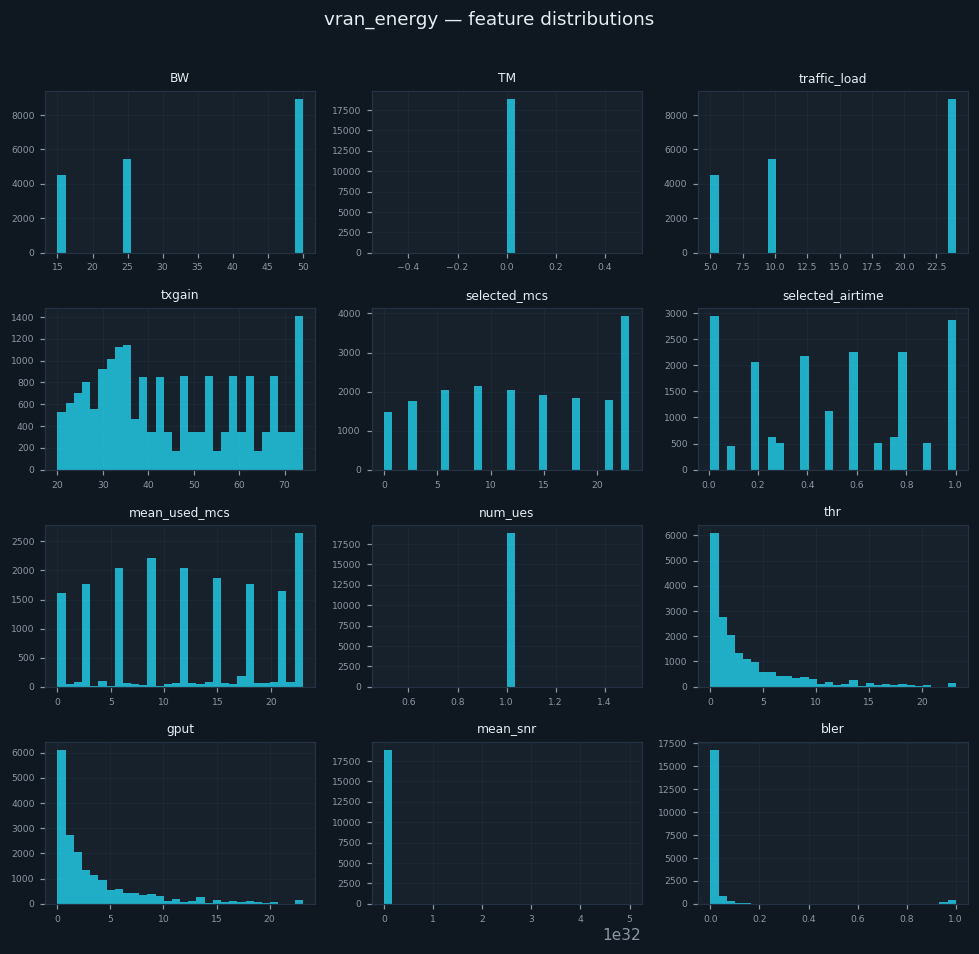

In [2]:
ds = build_dataset("vran_energy", max_rows=20000, seed=42)
print(ds.describe())
print("target:", ds.meta.get("target"))
display(VZ.fig_feature_histograms(ds, max_features=12))

base metrics: {'r2': 0.9678, 'mae': 1.3528}


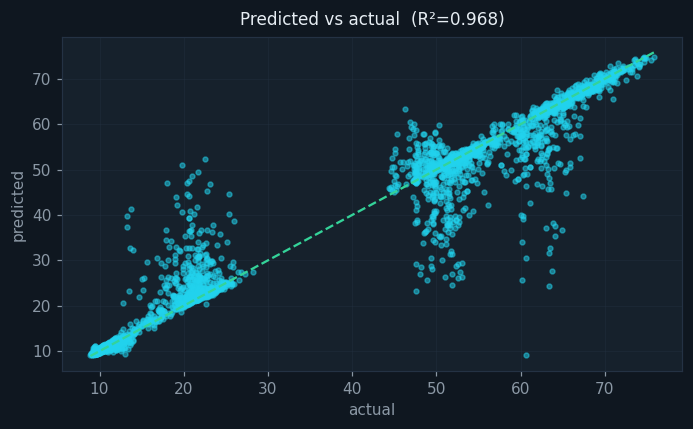

In [3]:
split = train_test_split_dataset(ds, test_size=0.3, seed=42, scale=True)
model = make_model("random_forest", split.train.task, split.feature_names, params={"n_estimators": 200})
model.fit(split.X_train, split.y_train)
print("base metrics:", {k: round(v,4) for k,v in model.score(split.X_test, split.y_test).items()})
display(VZ.fig_regression_scatter(split.y_test, model.predict(split.X_test)))

## Explainability (regression target)

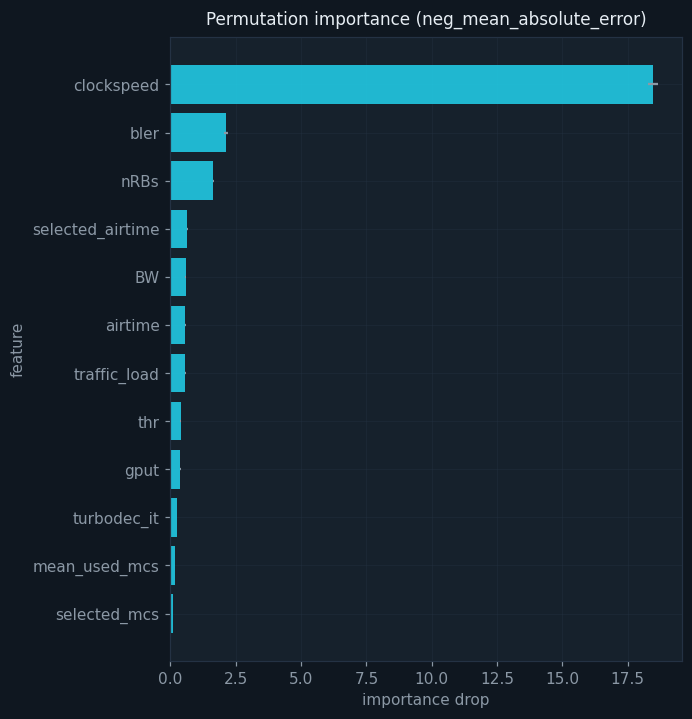

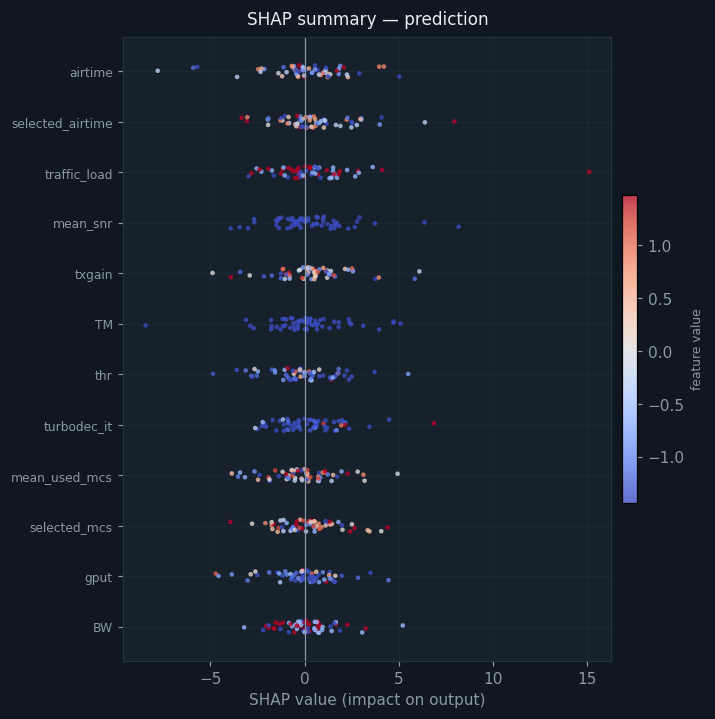

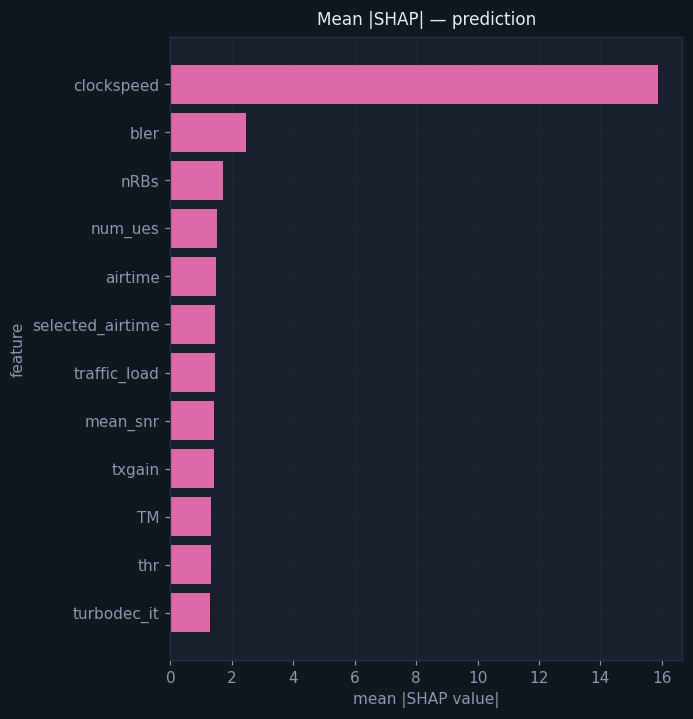

In [4]:
gi = EX.global_importance(model, split.X_test, split.y_test, n_repeats=8, seed=42)
display(VZ.fig_permutation_importance(gi))
rng = np.random.default_rng(1)
bg = split.X_train[rng.choice(len(split.X_train), 120, replace=False)]
ex = split.X_test[rng.choice(len(split.X_test), 60, replace=False)]
sh = EX.shap_explain(model, ex, bg, seed=42)   # regression -> no target_class
display(VZ.fig_shap_summary(sh))
display(VZ.fig_shap_bar(sh))

## Robustness — noise drift (R² degradation)

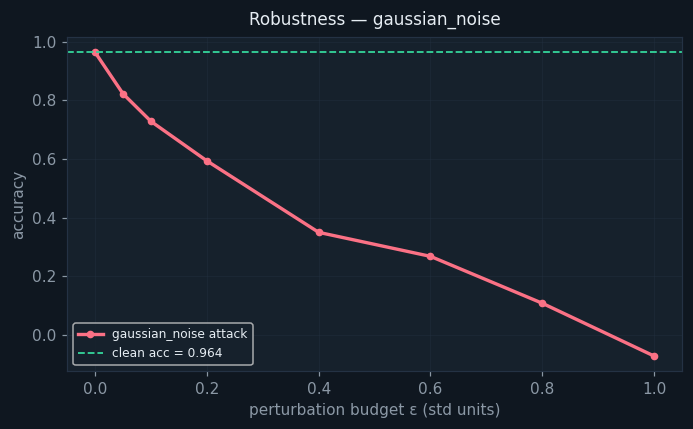

In [5]:
rc = RB.regression_noise_drift(model, split.X_test[:800], split.y_test[:800],
                               sigma_range=(0.0,0.05,0.1,0.2,0.4,0.6,0.8,1.0), seed=42)
display(VZ.fig_robustness_curve(rc))

## Fairness — error parity across CPU platforms

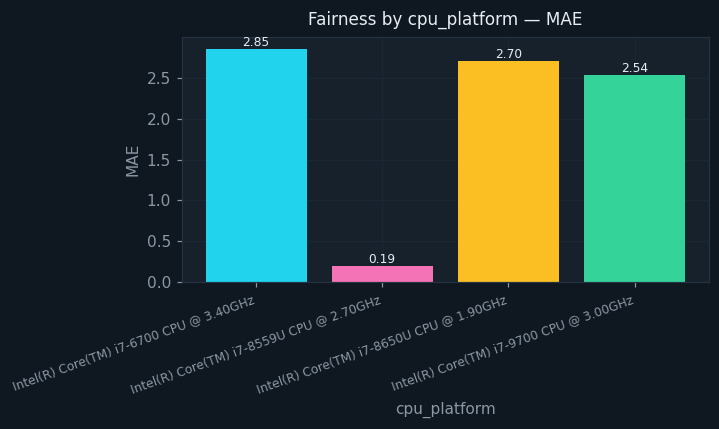

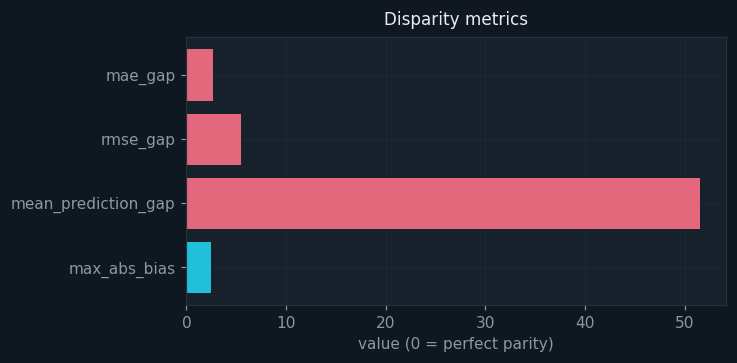

,group,n,mean_prediction,mean_actual,mae,rmse,bias
0,Intel(R) Core(TM) i7-6700 CPU @ 3.40GHz,928,50.285130,51.573749,2.854834,5.486258,-1.288619
1,Intel(R) Core(TM) i7-8559U CPU @ 2.70GHz,3052,11.067253,11.052193,0.192619,0.279054,0.015060
2,Intel(R) Core(TM) i7-8650U CPU @ 1.90GHz,884,22.423425,19.965944,2.703107,5.569080,2.457481
3,Intel(R) Core(TM) i7-9700 CPU @ 3.00GHz,804,62.624503,64.611486,2.538480,5.771653,-1.986983


In [6]:
groups = split.test.group_values("cpu_platform")
fr = FA.analyze_fairness(model, split.X_test, split.y_test, groups, "cpu_platform",
                         task=split.train.task)
display(VZ.fig_fairness_groups(fr))
display(VZ.fig_fairness_metrics(fr))
fr.group_table

## Privacy — DP for regression

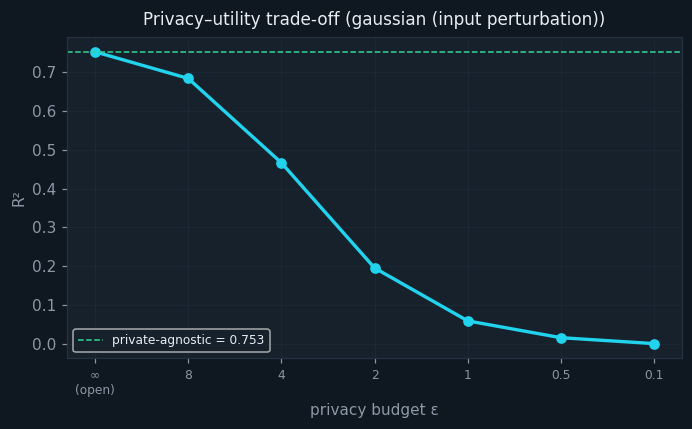

In [7]:
dp = PR.privacy_utility_curve(split.X_train[:4000], split.y_train[:4000],
                              split.X_test[:4000], split.y_test[:4000], split.train.task,
                              eps_range=(float("inf"),8.0,4.0,2.0,1.0,0.5,0.1), seed=42)
display(VZ.fig_dp_curve(dp))